In [5]:
path = '/content/drive/MyDrive/UniiGroningen/AML/dataset/pdebench_burgers_core.npz'
# give pdebench_burgers_core.npz as path !!

In [6]:
import numpy as np
import os
import torch
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt
import seaborn as sns
from torch.utils.data import Subset
import random

d = np.load(path)
for key in d.files:
    print(f"{key}: shape = {d[key].shape}")

train_field: shape = (240, 128)
train_target: shape = (240, 128)
train_context: shape = (240, 2)
train_coordinates: shape = (128,)
eval_128_field: shape = (60, 128)
eval_128_target: shape = (60, 128)
eval_128_context: shape = (60, 2)
eval_128_coordinates: shape = (128,)
eval_256_field: shape = (60, 256)
eval_256_target: shape = (60, 256)
eval_256_context: shape = (60, 2)
eval_256_coordinates: shape = (256,)
eval_512_field: shape = (60, 512)
eval_512_target: shape = (60, 512)
eval_512_context: shape = (60, 2)
eval_512_coordinates: shape = (512,)


# EVALUATION DATASETS

##1. save as files from pdebench_burgers_core.npz

In [7]:
data = np.load(path)
output_folder = 'bucketed_datasets'
os.makedirs(output_folder, exist_ok=True)

def process_and_save_eval(res):
    field = data[f'eval_{res}_field'] #takes the eval array of field from 128/256/512
    target = data[f'eval_{res}_target']
    context = data[f'eval_{res}_context']
    coords = data[f'eval_{res}_coordinates']

    roughness_scores = np.mean(np.abs(np.diff(field, axis=1)), axis=1)
    sorted_idx = np.argsort(roughness_scores)  #60 indexes of smooth/medium/rough values
    smooth_idx, medium_idx, rough_idx = np.array_split(sorted_idx, 3) #first 20 indexes-smooth next 20 medium next 20 rough

    print(f"Resolution {res} - Smooth: {len(smooth_idx)}, Medium: {len(medium_idx)}, Rough: {len(rough_idx)}")

    # Using indexes to extract original values then save
    np.savez(f'{output_folder}/eval_{res}_smooth.npz',
             field=field[smooth_idx],
             target=target[smooth_idx],
             context=context[smooth_idx],
             coordinates=coords)

    np.savez(f'{output_folder}/eval_{res}_medium.npz',
             field=field[medium_idx],
             target=target[medium_idx],
             context=context[medium_idx],
             coordinates=coords)

    np.savez(f'{output_folder}/eval_{res}_rough.npz',
             field=field[rough_idx],
             target=target[rough_idx],
             context=context[rough_idx],
             coordinates=coords)

for resolution in [128, 256, 512]:
    process_and_save_eval(resolution)

Resolution 128 - Smooth: 20, Medium: 20, Rough: 20
Resolution 256 - Smooth: 20, Medium: 20, Rough: 20
Resolution 512 - Smooth: 20, Medium: 20, Rough: 20


## 2. arrays from eval (use either one)

In [14]:
path128 = np.load('/content/drive/MyDrive/UniiGroningen/AML/dataset/eval_128.npz')
path256 = np.load('/content/drive/MyDrive/UniiGroningen/AML/dataset/eval_256.npz')
path512 = np.load('/content/drive/MyDrive/UniiGroningen/AML/dataset/eval_512.npz')

for key in path128.keys():
    print(f"{key}: shape = {path128[key].shape}")

field: shape = (60, 128)
target: shape = (60, 128)
context: shape = (60, 2)
coordinates: shape = (128,)


###128 *arrays*

In [17]:
field = path128[f'field']
target = path128[f'target']
context = path128[f'context']
coords = path128[f'coordinates']

roughness_scores = np.mean(np.abs(np.diff(field, axis=1)), axis=1)
sorted_idx = np.argsort(roughness_scores)
smooth_idx, medium_idx, rough_idx = np.array_split(sorted_idx, 3)

eval_bucket_128_smooth = {
    'field': field[smooth_idx],
    'target': target[smooth_idx],
    'context': context[smooth_idx],
    'coordinates': coords
}

eval_bucket_128_medium = {
    'field': field[medium_idx],
    'target': target[medium_idx],
    'context': context[medium_idx],
    'coordinates': coords
}

eval_bucket_128_rough = {
    'field': field[rough_idx],
    'target': target[rough_idx],
    'context': context[rough_idx],
    'coordinates': coords
}

###256 **arrays**

In [18]:
field = path256[f'field']
target = path256[f'target']
context = path256[f'context']
coords = path256[f'coordinates']

roughness_scores = np.mean(np.abs(np.diff(field, axis=1)), axis=1)
sorted_idx = np.argsort(roughness_scores)
smooth_idx, medium_idx, rough_idx = np.array_split(sorted_idx, 3)

eval_bucket_256_smooth = {
    'field': field[smooth_idx],
    'target': target[smooth_idx],
    'context': context[smooth_idx],
    'coordinates': coords
}

eval_bucket_256_medium = {
    'field': field[medium_idx],
    'target': target[medium_idx],
    'context': context[medium_idx],
    'coordinates': coords
}

eval_bucket_256_rough = {
    'field': field[rough_idx],
    'target': target[rough_idx],
    'context': context[rough_idx],
    'coordinates': coords
}

###512 arrays

In [19]:
field = path512[f'field']
target = path512[f'target']
context = path512[f'context']
coords = path512[f'coordinates']

roughness_scores = np.mean(np.abs(np.diff(field, axis=1)), axis=1)
sorted_idx = np.argsort(roughness_scores)
smooth_idx, medium_idx, rough_idx = np.array_split(sorted_idx, 3)

eval_bucket_512_smooth = {
    'field': field[smooth_idx],
    'target': target[smooth_idx],
    'context': context[smooth_idx],
    'coordinates': coords
}

eval_bucket_512_medium = {
    'field': field[medium_idx],
    'target': target[medium_idx],
    'context': context[medium_idx],
    'coordinates': coords
}

eval_bucket_512_rough = {
    'field': field[rough_idx],
    'target': target[rough_idx],
    'context': context[rough_idx],
    'coordinates': coords
}

###Checking random wave in individual buckets

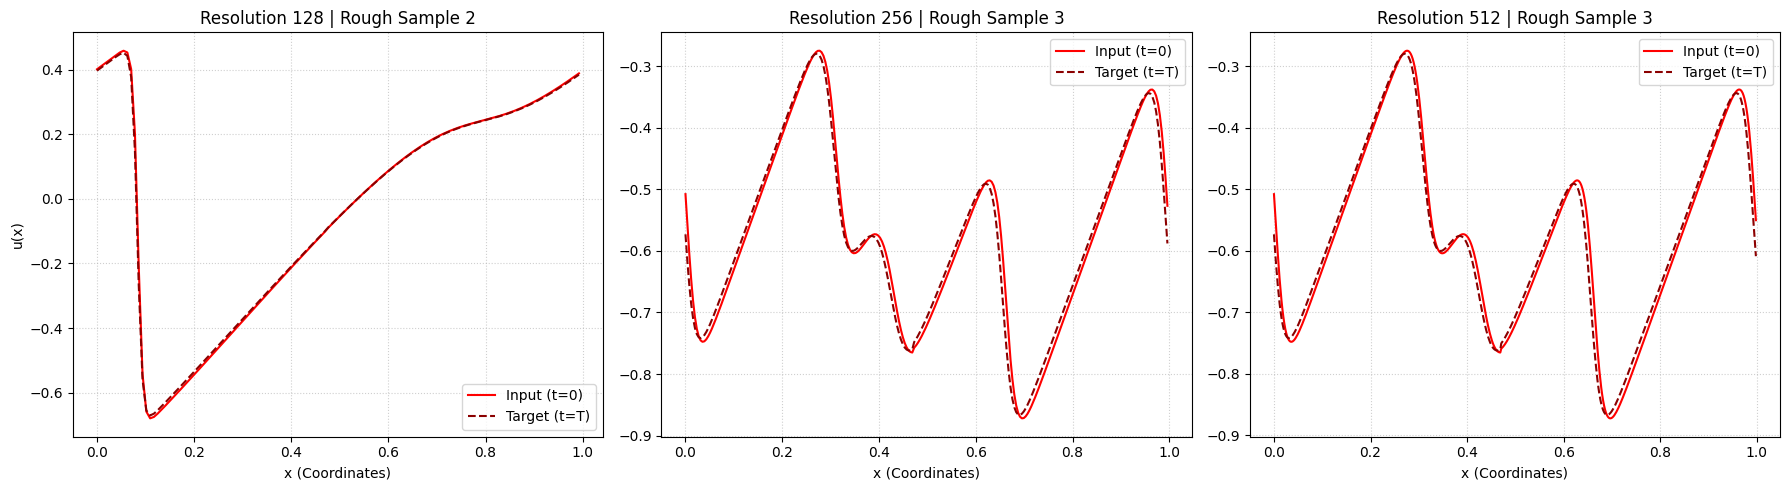

In [9]:
resolutions = [128, 256, 512]
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, res in enumerate(resolutions):
    data = np.load(f'bucketed_datasets/eval_{res}_rough.npz')
    fields = data['field']
    targets = data['target']
    coords = data['coordinates']

    idx = random.randint(0, fields.shape[0] - 1)
    axes[i].plot(coords, fields[idx], label='Input (t=0)', color='red')
    axes[i].plot(coords, targets[idx], label='Target (t=T)', color='darkred', linestyle='--')

    axes[i].set_title(f"Resolution {res} | Rough Sample {idx}")
    axes[i].set_xlabel("x (Coordinates)")
    if i == 0:
        axes[i].set_ylabel("u(x)")
    axes[i].legend()
    axes[i].grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

In [23]:
print(eval_bucket_128_rough['field'].shape)

(20, 128)


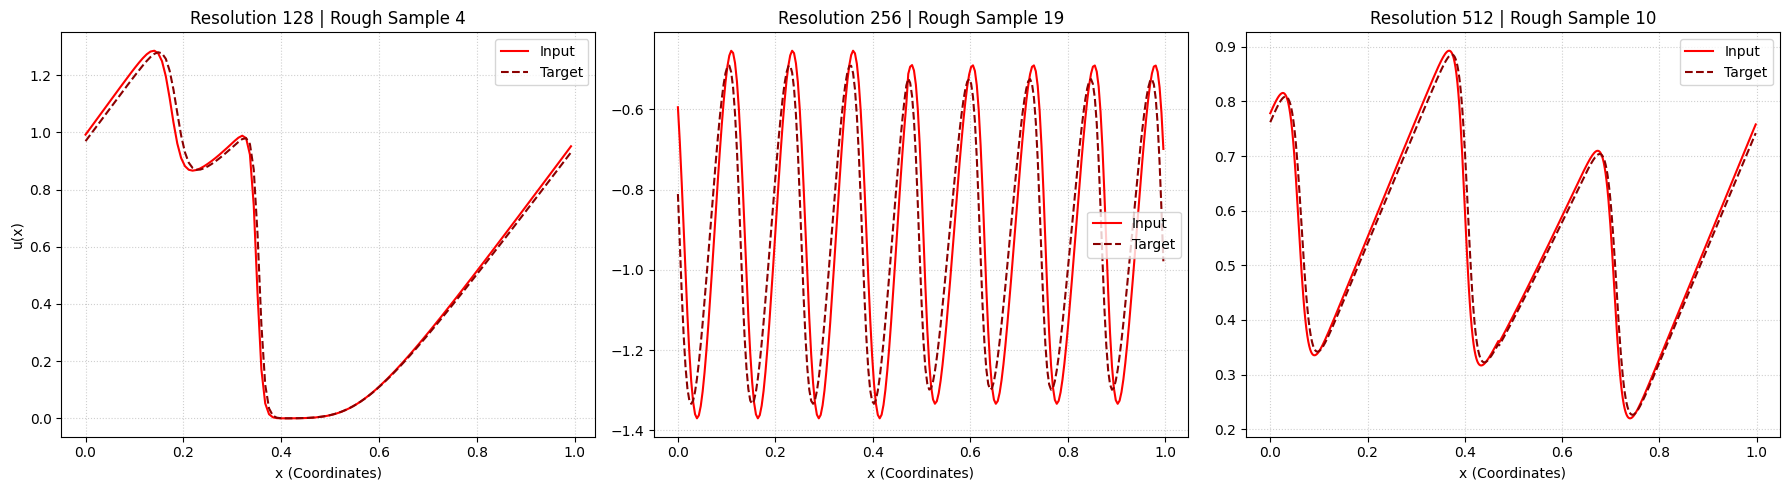

In [27]:
idx1 = random.randint(0, 19)
idx2 = random.randint(0, 19)
idx3 = random.randint(0, 19)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].plot(eval_bucket_128_rough['coordinates'], eval_bucket_128_rough['field'][idx1], label='Input', color='red')
axes[0].plot(eval_bucket_128_rough['coordinates'], eval_bucket_128_rough['target'][idx1], label='Target', color='darkred', linestyle='--')
axes[0].set_title(f"Resolution 128 | Rough Sample {idx1}")
axes[0].set_xlabel("x (Coordinates)")
axes[0].set_ylabel("u(x)")
axes[0].legend()
axes[0].grid(True, linestyle=':', alpha=0.6)

axes[1].plot(eval_bucket_256_rough['coordinates'], eval_bucket_256_rough['field'][idx2], label='Input', color='red')
axes[1].plot(eval_bucket_256_rough['coordinates'], eval_bucket_256_rough['target'][idx2], label='Target', color='darkred', linestyle='--')
axes[1].set_title(f"Resolution 256 | Rough Sample {idx2}")
axes[1].set_xlabel("x (Coordinates)")
axes[1].legend()
axes[1].grid(True, linestyle=':', alpha=0.6)

axes[2].plot(eval_bucket_512_rough['coordinates'], eval_bucket_512_rough['field'][idx3], label='Input', color='red')
axes[2].plot(eval_bucket_512_rough['coordinates'], eval_bucket_512_rough['target'][idx3], label='Target', color='darkred', linestyle='--')
axes[2].set_title(f"Resolution 512 | Rough Sample {idx3}")
axes[2].set_xlabel("x (Coordinates)")
axes[2].legend()
axes[2].grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

###Dataloaders and pytorch tensors

In [28]:
class DynamicsDataset(Dataset):
    def __init__(self, data_dict):
        self.field = data_dict['field']
        self.target = data_dict['target']
        self.coords = data_dict['coordinates']
        self.context = data_dict['context']

        # Z-Score Normalization
        self.mean = np.mean(self.field)
        self.std = np.std(self.field)

        self.field = (self.field - self.mean) / self.std
        self.target = (self.target - self.mean) / self.std

        # Convert to PyTorch Tensors
        self.field_tensor = torch.tensor(self.field, dtype=torch.float32)
        self.target_tensor = torch.tensor(self.target, dtype=torch.float32)
        self.coords_tensor = torch.tensor(self.coords, dtype=torch.float32)
        self.context_tensor = torch.tensor(self.context, dtype=torch.float32)

    def __len__(self):
        return len(self.field)

    def __getitem__(self, idx):
        x = self.field_tensor[idx].unsqueeze(0)
        y = self.target_tensor[idx].unsqueeze(0)

        return x, y, self.coords_tensor, self.context_tensor[idx]

In [29]:
eval_128_rough_dataset = DynamicsDataset(eval_bucket_128_rough)
eval_256_rough_dataset = DynamicsDataset(eval_bucket_256_rough)
eval_512_rough_dataset = DynamicsDataset(eval_bucket_512_rough)

batch_size = 16

loader_128_rough = DataLoader(eval_128_rough_dataset, batch_size=batch_size, shuffle=False)#shuffle = false for benchmark consistency
loader_256_rough = DataLoader(eval_256_rough_dataset, batch_size=batch_size, shuffle=False)
loader_512_rough = DataLoader(eval_512_rough_dataset, batch_size=batch_size, shuffle=False)

print(f"128 Rough Batches: {len(loader_128_rough)}")

128 Rough Batches: 2
